In [1]:
import sys

sys.path.append("..")
import json
from pathlib import Path
import numpy as np
import os
import plotly.express as px
import pandas as pd
from typing import Optional
from classes.sample.sample_classes import SampleFRF
import matplotlib.pyplot as plt

In [2]:
path = Path("../data/sequence_2_frf")
files = os.listdir(path)

In [3]:
def build_df(frf: SampleFRF, label: Optional[str] = None) -> pd.DataFrame:
    data = {
        "frequency": [],
        "magnitude": [],
        "axis": [],
        "cable": [],
        "label": [],
        "tension": [],
    }
    cables = [1, 2, 3, 4]
    axes = ["x", "y", "z"]
    for cable in cables:
        cable_frf = getattr(frf, f"sample_c{cable}")
        for axis in axes:
            single_frf = getattr(cable_frf, axis)
            n = len(single_frf.frequencies)
            axis_list = [axis] * n
            cable_list = [cable] * n
            labels_list = [label] * n
            tensions_list = [cable_frf.tension] * n
            data["frequency"] += single_frf.frequencies
            data["magnitude"] += single_frf.abs
            data["axis"] += axis_list
            data["cable"] += cable_list
            data["label"] += labels_list
            data["tension"] += tensions_list
    return pd.DataFrame(data)

In [83]:
idxs = np.linspace(0, len(files) - 1, 2_000, dtype=int)
dfs = []
for idx in idxs:
    f = files[idx]
    with open(path / f, "r") as h:
        frf = SampleFRF(**json.load(h))
        temp = build_df(frf, label=idx)
        dfs.append(temp)
df = pd.concat(dfs).reset_index(drop=True)

df = df.sort_values(["frequency", "tension"], ascending=False)
df["magnitude_db"] = 20 * np.log10(df["magnitude"])
df["new_label"] = df["tension"].round(0).astype(str)

In [84]:
# px.line(
#     df.loc[df["cable"] == 1]
#     .loc[df["frequency"].between(0,128)],
#     #.loc[df["axis"] == "z"],
#     color="axis",
#     x="frequency",
#     y="magnitude",
#     facet_row="new_label",
# )

In [122]:
df_c1_y = df.loc[(df["cable"] == 1) & (df["axis"] == "y")]
df_c1_y_pv = df_c1_y[["frequency", "magnitude", "tension"]].pivot(
    columns="tension", values="magnitude", index="frequency"
)

t = df_c1_y_pv.columns.to_numpy()
f = df_c1_y_pv.index.to_numpy()
y = df_c1_y_pv.to_numpy()

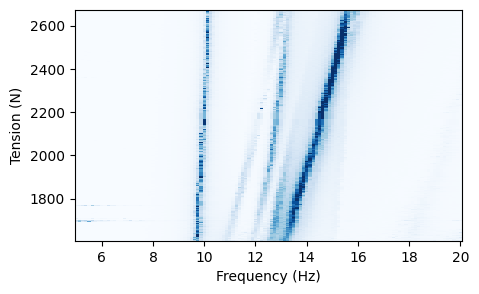

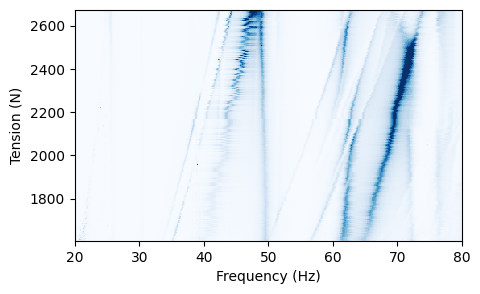

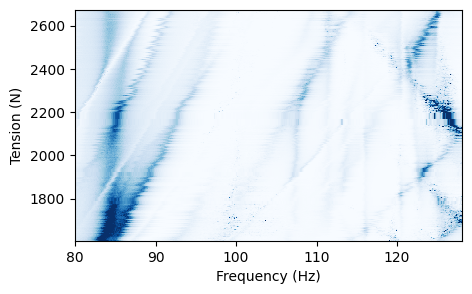

In [129]:
bands = [(5, 20), (20, 80), (80, 128)]
for f_start, f_end in bands:
    ind = (f >= f_start) & (f <= f_end)
    plt.figure(figsize=(5, 3))
    plt.pcolormesh(
        f[ind],
        t,
        y[ind,].T,
        cmap="Blues",
        vmin=np.quantile(y[ind,], 0.05),
        vmax=np.quantile(y[ind,], 0.995),
    )
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Tension (N)")